# TF–DNA predictions at human CUT&RUN binding sites (hg38)

This notebook evaluates the **hg38 TF–DNA checkpoint `hg38_3930720_epoch_18.ckpt`** on published human CUT&RUN peaks. Its analysis cells are the same as in `mm10_tf_dna_vs_cut&run.ipynb` (mm10); only the datasets, chromosomes, and checkpoint differ.

The question is whether the trained sequence model ranks experimentally bound windows above chromosome- and GC-matched genomic background, and whether it does better than a single motif scan of the same windows.

Run every code cell on an HPC **compute node**. No model fitting or threshold tuning is performed here. Primary analyses use the hg38 test chromosomes **chr20, chr21, and chr22**, conditional on an audit of the saved training and validation splits.

In [1]:
from pathlib import Path
import os
import socket
import sys

os.environ["PATH"] = os.path.dirname(sys.executable) + os.pathsep + os.environ["PATH"]

# Stop before importing scientific packages if the notebook is opened on a gateway.
if "hgtw" in socket.gethostname().lower() or "gtwy" in socket.gethostname().lower():
    raise RuntimeError("Run this notebook on a Slurm compute node")

PROJECT_DIR = Path("/gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER")
TETHER_DIR = PROJECT_DIR / "TETHER"
DATA_DIR = PROJECT_DIR / "data"
GENOME = "hg38"
sys.path.insert(0, str(TETHER_DIR))

import config

# The pipeline default for hg38 (config.hg38_tf_dna_path).
tf_dna_model_path = Path(config.hg38_tf_dna_path)
# The TF-DNA training cache of this genome (TF table, embeddings, splits).
tf_dna_input_cache_dir = config.tf_dna_cache_dir(GENOME)

cutrun_data_dir = DATA_DIR / "CUT&RUN_data" / "hg38"
tf_embedding_dir = DATA_DIR / "tf_data" / GENOME / "tf_embeddings"
cisbp_motif_dir = DATA_DIR / "databases" / "motif_information" / GENOME
genome_fasta_path = DATA_DIR / "genome_data" / "reference_genome" / GENOME / f"{GENOME}.fa"

run_label = f"tf_dna_cutrun_{GENOME}_{tf_dna_model_path.stem}"
evaluation_result_dir = TETHER_DIR / "new_testing_results" / run_label
evaluation_figure_dir = TETHER_DIR / "new_plots" / run_label
evaluation_result_dir.mkdir(parents=True, exist_ok=True)
evaluation_figure_dir.mkdir(parents=True, exist_ok=True)

import bisect
import gzip
import hashlib
import json
import logging
import platform
import re
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import torch
import sklearn
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.font_manager as font_manager
import pysam
from IPython.display import display, Markdown
from sklearn.metrics import (
    roc_curve, precision_recall_curve, roc_auc_score,
    average_precision_score, confusion_matrix,
)
import utils
from matplotlib_inline import backend_inline

get_ipython().run_line_magic("matplotlib", "inline")
backend_inline.set_matplotlib_formats("svg")

logging.basicConfig(level=logging.INFO, format="%(asctime)s - %(levelname)s - %(message)s")
logging.getLogger("fontTools").setLevel(logging.WARNING)

RANDOM_SEED = 42
EVALUATION_CHROMOSOMES = ('chr20', 'chr21', 'chr22')
DNA_WINDOW_LENGTH = 256
GC_MATCH_TOLERANCE = 0.02
MAXIMUM_MATCH_ATTEMPTS = 5000
INFERENCE_BATCH_SIZE = 128
BOOTSTRAP_REPLICATES = 500

torch.manual_seed(RANDOM_SEED)
torch.set_num_threads(min(4, int(os.environ.get("SLURM_CPUS_PER_TASK", "4"))))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Host: {socket.gethostname()} | device: {device}")
print(f"Checkpoint: {tf_dna_model_path}")
print(f"TF-DNA cache: {tf_dna_input_cache_dir}")

Host: psh01com1hgpu01 | device: cuda
Checkpoint: /gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER/TETHER/checkpoints/new_tf_dna_models/hg38_3930720_epoch_18.ckpt
TF-DNA cache: /gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER/TETHER/cached_data/hg38/tf_dna_cache_site_merged_overlap_filtered


## Data sources and scope

| Dataset | TF | GEO | Biological material | Peaks |
|---|---|---|---|---|
| CTCF_K562 | CTCF | [GSE239324](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE239324) (GSM7663176–7) | K562, empty-vector control, merged replicates | MACS2 narrowPeak, **hg19 lifted to hg38** |
| EPAS1_786O_rep1–3 | EPAS1 (HIF-2α) | [GSE207573](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE207573) (GSM6297408–10) | 786-O, **endogenous** V5-Halo-HIF-2α knock-in, anti-V5 | MACS2 narrowPeak vs IgG, hg38 |
| HIF1A_786O_rep1–3 | HIF1A | GSE207573 (GSM6297426–28) | 786-O, **exogenous** V5-Halo-HIF-1α, anti-V5 | MACS2 narrowPeak vs IgG, hg38 |
| V5_control_786O | (scored as EPAS1) | GSE207573 (GSM6297402–04) | Wild-type 786-O, anti-V5, **no tagged protein** | Union of 3 replicates |

CTCF is the broadly binding reference. No human lineage-restricted TF (the role of NANOG in the mm10 notebook) is included: the GATA2/GATA3 trophoblast CUT&RUN peaks of GSE214486 were tested and removed because the GATA motif is not enriched in them, and the K562 TAL1 CUT&RUN of GSE272339 has 41 wild-type peaks genome-wide, none on chr20–22. HIF-2α is the endogenous HIF-α in 786-O cells (VHL-null, constitutively stabilized); 786-O cells do not express endogenous HIF-1α, so HIF1A peaks come from an exogenous construct.

Two derived sets are primary for the HIF factors: **replicate-1 peaks that overlap a peak in both other replicates and do not overlap any wild-type anti-V5 peak** (`*_reproducible`). This is a reproducibility and specificity filter, **not an IDR analysis**. The wild-type anti-V5 peaks have no tagged protein to bind, so they show the assay's non-specific signal; scoring them with the EPAS1 embedding tests whether the model ranks any CUT&RUN-enriched region above background.

Download commands are in `TETHER/bash_scripts/download_hg38_cutrun_peaks.sh`; GEO SOFT metadata, SHA-256 checksums, and the liftOver unmapped records are kept in `data/CUT&RUN_data/hg38/`. The [ENCODE hg38 blacklist v2](https://github.com/Boyle-Lab/Blacklist) removes problematic regions from both classes. Local reference lengths are checked against [UCSC hg38](https://hgdownload.soe.ucsc.edu/goldenPath/hg38/bigZips/hg38.chrom.sizes).

In [2]:
def hif_file(pair):
    return f"GSE207573_{pair}_peaks_peaks.removedblacklist.narrowPeak.gz"

cutrun_dataset_definitions = [
    dict(dataset="CTCF_K562", tf_name="CTCF", series="GSE239324", geo_samples=["GSM7663176", "GSM7663177"],
         title_keyword="EV CTCF", assembly="hg19", file_format="narrowPeak", role="primary",
         exclusion_group="CTCF", files=["GSE239324_EV_CTCF.hg38_liftover.narrowPeak.gz"]),
]
for tf_name, label, samples, pairs in (
    ("EPAS1", "HIF-2a KIN, anti-V5", ["GSM6297408", "GSM6297409", "GSM6297410"],
     ["YC034_on_YC028", "YC058_on_YC052", "YC072_on_YC065"]),
    ("HIF1A", "HIF-1a, anti-V5", ["GSM6297426", "GSM6297427", "GSM6297428"],
     ["YC037_on_YC031", "YC061_on_YC055", "YC075_on_YC068"]),
):
    for replicate, (sample, pair) in enumerate(zip(samples, pairs), start=1):
        cutrun_dataset_definitions.append(dict(
            dataset=f"{tf_name}_786O_rep{replicate}", tf_name=tf_name, series="GSE207573",
            geo_samples=[sample], title_keyword=label, assembly="hg38", file_format="narrowPeak",
            role="replicate", exclusion_group=tf_name, files=[hif_file(pair)],
        ))
cutrun_dataset_definitions.append(dict(
    dataset="V5_control_786O", tf_name="EPAS1", series="GSE207573",
    geo_samples=["GSM6297402", "GSM6297403", "GSM6297404"], title_keyword="WT, anti-V5",
    assembly="hg38", file_format="narrowPeak", role="control", exclusion_group="V5_control",
    files=[hif_file(pair) for pair in ("YC033_on_YC027", "YC057_on_YC051", "YC071_on_YC064")],
))
# Derived primary sets: anchor peaks that overlap every "require" set and no "exclude" set.
REPRODUCIBLE_SETS = [
    dict(dataset=f"{tf_name}_786O_reproducible", anchor=f"{tf_name}_786O_rep1",
         require=[f"{tf_name}_786O_rep2", f"{tf_name}_786O_rep3"], exclude=["V5_control_786O"],
         description="replicate-1 peaks overlapping replicates 2 and 3, none overlapping wild-type anti-V5")
    for tf_name in ("EPAS1", "HIF1A")
]
# Short consensus per TF for the motif QC table (supporting information only).
CONSENSUS_PATTERNS = {
    "RCGTG": r"(?=[AG]CGTG|CACG[CT])",  # hypoxia response element core
    "CCCTC": r"(?=CCCTC|GAGGG)",  # CTCF core
}
OWN_CONSENSUS = {"EPAS1": "RCGTG", "HIF1A": "RCGTG", "CTCF": "CCCTC"}
EXTRA_PROVENANCE_FILES = ["GSE239324_EV_CTCF.narrowPeak.gz"]

EVALUATED_TFS = sorted({item["tf_name"] for item in cutrun_dataset_definitions})

required_paths = [
    tf_dna_model_path, genome_fasta_path,
    cutrun_data_dir / f"{GENOME}-blacklist.v2.bed.gz",
    cutrun_data_dir / f"{GENOME}.chrom.sizes",
    *[cutrun_data_dir / filename for item in cutrun_dataset_definitions for filename in item["files"]],
]
for required_path in required_paths:
    if not required_path.is_file() or required_path.stat().st_size == 0:
        raise FileNotFoundError(required_path)

# Check sample identity, antibody, and assembly from the downloaded GEO metadata.
def read_geo_sample_metadata(series_accession):
    with gzip.open(cutrun_data_dir / f"{series_accession}_family.soft.gz", "rt") as handle:
        sample_blocks = handle.read().split("^SAMPLE = ")[1:]
    return {block.splitlines()[0].strip(): block for block in sample_blocks}

geo_metadata_by_series = {
    series: read_geo_sample_metadata(series)
    for series in sorted({item["series"] for item in cutrun_dataset_definitions})
}
for dataset_definition in cutrun_dataset_definitions:
    for sample in dataset_definition["geo_samples"]:
        sample_metadata = geo_metadata_by_series[dataset_definition["series"]][sample]
        sample_title = next(line for line in sample_metadata.splitlines() if line.startswith("!Sample_title"))
        assert dataset_definition["assembly"] in sample_metadata, (sample, dataset_definition["assembly"])
        assert dataset_definition["title_keyword"].lower() in sample_title.lower(), (sample, sample_title)
        print(f"{dataset_definition['dataset']:<18} {sample} {dataset_definition['assembly']} {sample_title}")

genome_fasta = pysam.FastaFile(str(genome_fasta_path))
ucsc_chromosome_sizes = pd.read_csv(
    cutrun_data_dir / f"{GENOME}.chrom.sizes", sep="\t", header=None,
    names=["chromosome", "length"],
).set_index("chromosome")["length"].to_dict()
for chromosome in [f"chr{i}" for i in range(1, 23)] + ["chrX"]:
    assert genome_fasta.get_reference_length(chromosome) == ucsc_chromosome_sizes[chromosome]
print(f"Local reference lengths match UCSC {GENOME} for chromosomes 1–22 and X.")

CTCF_K562          GSM7663176 hg19 !Sample_title = EV CTCF rep1
CTCF_K562          GSM7663177 hg19 !Sample_title = EV CTCF rep2
EPAS1_786O_rep1    GSM6297408 hg38 !Sample_title = HIF-2a KIN, anti-V5, rep1 [CUT&Run]
EPAS1_786O_rep2    GSM6297409 hg38 !Sample_title = HIF-2a KIN, anti-V5, rep2 [CUT&Run]
EPAS1_786O_rep3    GSM6297410 hg38 !Sample_title = HIF-2a KIN, anti-V5, rep3 [CUT&Run]
HIF1A_786O_rep1    GSM6297426 hg38 !Sample_title = HIF-1a, anti-V5, rep1 [CUT&Run]
HIF1A_786O_rep2    GSM6297427 hg38 !Sample_title = HIF-1a, anti-V5, rep2 [CUT&Run]
HIF1A_786O_rep3    GSM6297428 hg38 !Sample_title = HIF-1a, anti-V5, rep3 [CUT&Run]
V5_control_786O    GSM6297402 hg38 !Sample_title = WT, anti-V5, rep1 [CUT&Run]
V5_control_786O    GSM6297403 hg38 !Sample_title = WT, anti-V5, rep2 [CUT&Run]
V5_control_786O    GSM6297404 hg38 !Sample_title = WT, anti-V5, rep3 [CUT&Run]
Local reference lengths match UCSC hg38 for chromosomes 1–22 and X.


## Verify the saved chromosome splits

The hg38 TF–DNA cache assigns human chromosomes 1–17 to training, 18–19 to validation, and 20–22 to testing. We verify this against the **persisted edge indices and peak mapping** of the cache, rather than creating new splits. The audit includes all TFs, because training on a chromosome with any TF would weaken a claim that its sequences were unseen.

The checkpoint does not contain a cryptographic link to that cache, so this cannot by itself prove historical cache identity. The test chromosomes may overlap the model's original ChIP-seq test examples; this is an assay-transfer evaluation on held-out chromosomes, not proof of novel loci or an unseen TF.

In [3]:
cached_peak_onehot = torch.load(
    tf_dna_input_cache_dir / "peak_onehot_array.pt", map_location="cpu",
    mmap=True, weights_only=True,
)
assert tuple(cached_peak_onehot.shape[1:]) == (DNA_WINDOW_LENGTH, 4), cached_peak_onehot.shape
number_of_cached_peaks = len(cached_peak_onehot)
cached_edge_peak_indices = torch.load(
    tf_dna_input_cache_dir / "edge_peak_idx.pt", map_location="cpu",
    mmap=True, weights_only=True,
).numpy()
split_peak_membership = {}
split_edge_counts = {}
for split_name in ("train", "val", "test"):
    saved_edge_indices = torch.load(
        tf_dna_input_cache_dir / f"{split_name}_idx.pt", map_location="cpu", weights_only=True,
    ).numpy()
    assert saved_edge_indices.min() >= 0 and saved_edge_indices.max() < len(cached_edge_peak_indices)
    peak_membership = np.zeros(number_of_cached_peaks, dtype=bool)
    peak_membership[cached_edge_peak_indices[saved_edge_indices]] = True
    split_peak_membership[split_name] = peak_membership
    split_edge_counts[split_name] = len(saved_edge_indices)
    del saved_edge_indices
split_chromosomes = {name: set() for name in split_peak_membership}
split_heldout_peak_counts = {name: 0 for name in split_peak_membership}

# Read the large mapping in chunks; the tensors remain memory-mapped.
for peak_mapping_chunk in pd.read_csv(
    tf_dna_input_cache_dir / "peak_id_to_idx.csv", chunksize=500_000,
):
    peak_indices = peak_mapping_chunk["peak_idx"].to_numpy()
    chromosome_names = peak_mapping_chunk["peak_id"].str.split(":", n=1).str[0]
    for split_name, membership in split_peak_membership.items():
        selected = membership[peak_indices]
        split_chromosomes[split_name].update(chromosome_names[selected].unique())
        split_heldout_peak_counts[split_name] += int(
            (selected & chromosome_names.isin(EVALUATION_CHROMOSOMES)).sum()
        )

split_audit_df = pd.DataFrame([
    dict(split=split_name, edges=split_edge_counts[split_name],
         chromosomes=",".join(sorted(split_chromosomes[split_name], key=lambda c: (len(c), c))),
         peaks_on_evaluation_chromosomes=split_heldout_peak_counts[split_name])
    for split_name in split_chromosomes
])
display(split_audit_df)
assert not set(EVALUATION_CHROMOSOMES) & split_chromosomes["train"]
assert not set(EVALUATION_CHROMOSOMES) & split_chromosomes["val"]
assert set(EVALUATION_CHROMOSOMES) <= split_chromosomes["test"]
split_audit_df.to_csv(evaluation_result_dir / "saved_split_audit.tsv", sep="\t", index=False)
del split_peak_membership, cached_edge_peak_indices, cached_peak_onehot

,split,edges,chromosomes,peaks_on_evaluation_chromosomes
0,train,21371874,"chr1,chr2,chr3,chr4,chr5,chr6,chr7,chr8,chr9,c...",0
1,val,1433172,"chr18,chr19",0
2,test,1795335,"chr20,chr21,chr22",1080120


## Define positive and background windows

1. Parse narrowPeak or BED files as positives:
    - Keep chr20–22, validate peak coordinates, and drop duplicate windows.
    - Center a 256-bp window on the summit (narrowPeak) or the peak midpoint (BED).
    - Remove windows that extend past the chromosome, overlap the blacklist, overlap another retained window, or contain anything except A/C/G/T.

2. Derive the reproducible HIF sets: replicate-1 peaks that overlap a peak in both other replicates and no wild-type anti-V5 peak.

3. For each retained positive:
    - Sample a 256-bp genomic background window from the **same chromosome**, with GC fraction within 0.02 of the positive.
    - Reject any background that overlaps a peak of the same exclusion group (all replicates of that TF), the blacklist, a positive window, or a previously selected background window.

4. Save the complete table, sequences, labels, source peak coordinates, and pair identifiers **before inference**.

Windows are labeled 1 if they come from CUT&RUN peaks and 0 if they are sampled background. The background seed is `RANDOM_SEED` plus the dataset's position in the list, so adding or removing a dataset changes the backgrounds of the datasets after it.

In [4]:
narrowpeak_columns = [
    "chromosome", "peak_start", "peak_end", "peak_name", "peak_score", "strand",
    "signal_value", "negative_log10_pvalue", "negative_log10_qvalue", "summit_offset",
]

def make_interval_lookup(interval_df):
    # Prefix maxima support overlap tests even when intervals overlap or nest.
    lookup = {}
    for chromosome, chromosome_df in interval_df.groupby("chromosome", sort=False):
        ordered = chromosome_df.sort_values("start")
        lookup[chromosome] = (
            ordered["start"].to_numpy(dtype=np.int64),
            np.maximum.accumulate(ordered["end"].to_numpy(dtype=np.int64)),
        )
    return lookup

def interval_overlaps(lookup, chromosome, start, end):
    if chromosome not in lookup:
        return False
    starts, maximum_ends = lookup[chromosome]
    position = np.searchsorted(starts, end, side="left") - 1
    return bool(position >= 0 and maximum_ends[position] > start)

def peak_interval_lookup(peak_df):
    return make_interval_lookup(peak_df.rename(columns={"peak_start": "start", "peak_end": "end"}))

def read_cutrun_peaks(filename, file_format):
    peak_df = pd.read_csv(cutrun_data_dir / filename, sep="\t", header=None, comment="#")
    if file_format == "narrowPeak":
        if peak_df.shape[1] != 10:
            raise ValueError(f"Expected 10 narrowPeak columns in {filename}; got {peak_df.shape[1]}")
        peak_df.columns = narrowpeak_columns
    else:
        if peak_df.shape[1] < 3:
            raise ValueError(f"Expected at least 3 BED columns in {filename}")
        peak_df = peak_df.iloc[:, :4].copy()
        peak_df.columns = ["chromosome", "peak_start", "peak_end", "peak_name"][:peak_df.shape[1]]
        peak_df["signal_value"] = np.nan
        peak_df["summit_offset"] = -1  # BED has no summit: the window is centered on the midpoint.
    for column in ("peak_start", "peak_end", "summit_offset"):
        peak_df[column] = pd.to_numeric(peak_df[column], errors="raise").astype(np.int64)
    peak_df["source_file"] = filename
    return peak_df

raw_peak_tables = {
    item["dataset"]: pd.concat(
        [read_cutrun_peaks(filename, item["file_format"]) for filename in item["files"]],
        ignore_index=True,
    )
    for item in cutrun_dataset_definitions
}

# Derived reproducible sets (see REPRODUCIBLE_SETS in the dataset cell).
for reproducible_set in REPRODUCIBLE_SETS:
    anchor_df = raw_peak_tables[reproducible_set["anchor"]]
    require_lookups = [peak_interval_lookup(raw_peak_tables[name]) for name in reproducible_set["require"]]
    exclude_lookups = [peak_interval_lookup(raw_peak_tables[name]) for name in reproducible_set["exclude"]]
    keep = [
        all(interval_overlaps(lookup, row.chromosome, row.peak_start, row.peak_end) for lookup in require_lookups)
        and not any(interval_overlaps(lookup, row.chromosome, row.peak_start, row.peak_end) for lookup in exclude_lookups)
        for row in anchor_df.itertuples(index=False)
    ]
    raw_peak_tables[reproducible_set["dataset"]] = anchor_df.loc[keep].copy()
    member_names = [reproducible_set["anchor"], *reproducible_set["require"]]
    anchor_definition = next(item for item in cutrun_dataset_definitions if item["dataset"] == reproducible_set["anchor"])
    cutrun_dataset_definitions.append(dict(
        anchor_definition, dataset=reproducible_set["dataset"], role="primary",
        geo_samples=[sample for item in cutrun_dataset_definitions if item["dataset"] in member_names
                     for sample in item["geo_samples"]],
        files=[reproducible_set["description"]],
    ))
    print(f"{reproducible_set['dataset']}: {sum(keep):,} of {len(anchor_df):,} anchor peaks kept genome-wide")

blacklist_df = pd.read_csv(
    cutrun_data_dir / f"{GENOME}-blacklist.v2.bed.gz", sep="\t", header=None,
    usecols=[0, 1, 2], names=["chromosome", "start", "end"],
)
blacklist_lookup = make_interval_lookup(blacklist_df)

# Backgrounds avoid every peak of the same group (all replicates of that TF; the
# reproducible sets are subsets of their anchor, so including them changes nothing).
target_peak_exclusion_lookup = {}
for exclusion_group in sorted({item["exclusion_group"] for item in cutrun_dataset_definitions}):
    group_tables = [
        raw_peak_tables[item["dataset"]][["chromosome", "peak_start", "peak_end"]]
        for item in cutrun_dataset_definitions if item["exclusion_group"] == exclusion_group
    ]
    target_peak_exclusion_lookup[exclusion_group] = peak_interval_lookup(pd.concat(group_tables, ignore_index=True))

def is_unambiguous_dna(sequence):
    return len(sequence) == DNA_WINDOW_LENGTH and set(sequence) <= set("ACGT")

def gc_fraction(sequence):
    return (sequence.count("G") + sequence.count("C")) / len(sequence)

def cpg_fraction(sequence):
    return sequence.count("CG") / (len(sequence) - 1)

def make_matched_evaluation_table(dataset_definition, dataset_seed):
    dataset_name = dataset_definition["dataset"]
    tf_name = dataset_definition["tf_name"]
    exclusion_lookup = target_peak_exclusion_lookup[dataset_definition["exclusion_group"]]
    raw_peak_df = raw_peak_tables[dataset_name]
    qc_counts = dict(dataset=dataset_name, tf_name=tf_name, role=dataset_definition["role"],
                     raw_peaks=len(raw_peak_df))
    chromosome_peak_df = raw_peak_df.loc[raw_peak_df["chromosome"].isin(EVALUATION_CHROMOSOMES)].copy()
    qc_counts["peaks_on_evaluation_chromosomes"] = len(chromosome_peak_df)
    positive_records = []
    seen_window_coordinates = set()
    last_retained_end = {}
    for peak in chromosome_peak_df.sort_values(
        ["chromosome", "peak_start", "peak_end"], kind="stable",
    ).itertuples(index=False):
        chromosome_size = ucsc_chromosome_sizes[peak.chromosome]
        if not (0 <= peak.peak_start < peak.peak_end <= chromosome_size):
            continue
        summit_valid = 0 <= peak.summit_offset < peak.peak_end - peak.peak_start
        peak_center = (
            peak.peak_start + peak.summit_offset if summit_valid
            else (peak.peak_start + peak.peak_end) // 2
        )
        window_start = peak_center - DNA_WINDOW_LENGTH // 2
        window_end = window_start + DNA_WINDOW_LENGTH
        coordinates = (peak.chromosome, window_start, window_end)
        if window_start < 0 or window_end > chromosome_size or coordinates in seen_window_coordinates:
            continue
        if interval_overlaps(blacklist_lookup, *coordinates):
            continue
        sequence = genome_fasta.fetch(*coordinates).upper()
        if not is_unambiguous_dna(sequence):
            continue
        seen_window_coordinates.add(coordinates)
        positive_records.append(dict(
            chromosome=peak.chromosome, start=window_start, end=window_end,
            peak_start=peak.peak_start, peak_end=peak.peak_end, peak_name=str(peak.peak_name),
            signal_value=peak.signal_value, center_method="summit" if summit_valid else "midpoint",
            sequence=sequence, gc_fraction=gc_fraction(sequence), cpg_fraction=cpg_fraction(sequence),
        ))
    # Broad peaks can reorder summits, so overlap removal runs on window coordinates.
    positive_records.sort(key=lambda record: (record["chromosome"], record["start"], record["end"]))
    nonoverlapping_positives = []
    for record in positive_records:
        chromosome = record["chromosome"]
        if record["start"] >= last_retained_end.get(chromosome, -1):
            nonoverlapping_positives.append(record)
            last_retained_end[chromosome] = record["end"]
    qc_counts["valid_unique_windows"] = len(positive_records)
    qc_counts["nonoverlapping_positive_windows"] = len(nonoverlapping_positives)
    if not nonoverlapping_positives:
        raise ValueError(f"No eligible positive windows for {dataset_name}")
    positive_window_lookup = make_interval_lookup(pd.DataFrame(nonoverlapping_positives))
    random_generator = np.random.default_rng(dataset_seed)
    background_starts = {chromosome: [] for chromosome in EVALUATION_CHROMOSOMES}
    paired_records = []
    for positive in nonoverlapping_positives:
        chromosome = positive["chromosome"]
        selected_background = None
        for attempt in range(MAXIMUM_MATCH_ATTEMPTS):
            start = int(random_generator.integers(
                0, ucsc_chromosome_sizes[chromosome] - DNA_WINDOW_LENGTH + 1,
            ))
            end = start + DNA_WINDOW_LENGTH
            if interval_overlaps(exclusion_lookup, chromosome, start, end):
                continue
            if interval_overlaps(blacklist_lookup, chromosome, start, end):
                continue
            if interval_overlaps(positive_window_lookup, chromosome, start, end):
                continue
            existing_starts = background_starts[chromosome]
            insertion_position = bisect.bisect_left(existing_starts, start)
            if insertion_position > 0 and existing_starts[insertion_position - 1] + DNA_WINDOW_LENGTH > start:
                continue
            if insertion_position < len(existing_starts) and existing_starts[insertion_position] < end:
                continue
            sequence = genome_fasta.fetch(chromosome, start, end).upper()
            if not is_unambiguous_dna(sequence):
                continue
            background_gc_fraction = gc_fraction(sequence)
            if abs(background_gc_fraction - positive["gc_fraction"]) > GC_MATCH_TOLERANCE:
                continue
            bisect.insort(existing_starts, start)
            selected_background = dict(
                chromosome=chromosome, start=start, end=end,
                peak_start=-1, peak_end=-1, peak_name="matched_background",
                signal_value=np.nan, center_method="sampled",
                sequence=sequence, gc_fraction=background_gc_fraction,
                cpg_fraction=cpg_fraction(sequence),
            )
            break
        if selected_background is None:
            continue
        pair_id = f"{dataset_name}_pair_{len(paired_records) // 2:06d}"
        for label, record in ((1, positive), (0, selected_background)):
            paired_records.append(dict(
                dataset=dataset_name, tf_name=tf_name, role=dataset_definition["role"],
                accession=",".join(dataset_definition["geo_samples"]), pair_id=pair_id, label=label, **record,
            ))
    qc_counts["matched_pairs"] = len(paired_records) // 2
    qc_counts["unmatched_positives"] = len(nonoverlapping_positives) - qc_counts["matched_pairs"]
    if qc_counts["matched_pairs"] < 20:
        raise ValueError(f"Too few matched pairs for {dataset_name}: {qc_counts}")
    return pd.DataFrame(paired_records), qc_counts

evaluation_tables = []
dataset_qc_records = []
for dataset_number, dataset_definition in enumerate(cutrun_dataset_definitions):
    evaluation_table, qc_record = make_matched_evaluation_table(
        dataset_definition, RANDOM_SEED + dataset_number,
    )
    evaluation_tables.append(evaluation_table)
    dataset_qc_records.append(qc_record)
evaluation_windows_df = pd.concat(evaluation_tables, ignore_index=True)
evaluation_windows_df.insert(0, "row_id", np.arange(len(evaluation_windows_df)))
assert not evaluation_windows_df.duplicated(["dataset", "chromosome", "start", "end"]).any()
assert evaluation_windows_df.groupby("pair_id")["label"].agg(list).apply(lambda values: values == [1, 0]).all()

# Save inputs before scoring. These rows define the order of all later predictions.
evaluation_windows_path = evaluation_result_dir / "evaluation_windows.parquet"
evaluation_windows_df.to_parquet(evaluation_windows_path, index=False)
dataset_qc_df = pd.DataFrame(dataset_qc_records)
dataset_qc_df.to_csv(evaluation_result_dir / "dataset_qc.tsv", sep="\t", index=False)
display(dataset_qc_df)

EPAS1_786O_reproducible: 1,824 of 3,984 anchor peaks kept genome-wide
HIF1A_786O_reproducible: 7,351 of 15,058 anchor peaks kept genome-wide


,dataset,tf_name,role,raw_peaks,peaks_on_evaluation_chromosomes,valid_unique_windows,nonoverlapping_positive_windows,matched_pairs,unmatched_positives
0,CTCF_K562,CTCF,primary,26328,1872,1865,1865,1857,8
1,EPAS1_786O_rep1,EPAS1,replicate,3984,281,281,281,281,0
2,EPAS1_786O_rep2,EPAS1,replicate,13193,857,857,857,857,0
3,EPAS1_786O_rep3,EPAS1,replicate,7311,532,532,532,531,1
4,HIF1A_786O_rep1,HIF1A,replicate,15058,1148,1148,1148,1146,2
5,HIF1A_786O_rep2,HIF1A,replicate,20572,1506,1506,1506,1505,1
6,HIF1A_786O_rep3,HIF1A,replicate,15909,1155,1155,1155,1153,2
7,V5_control_786O,EPAS1,control,10643,725,725,684,684,0
8,EPAS1_786O_reproducible,EPAS1,primary,1824,125,125,125,125,0
9,HIF1A_786O_reproducible,HIF1A,primary,7351,551,551,551,548,3


## Load the checkpoint and TF embeddings

`utils.load_tf_dna_model` rebuilds the trainer's architecture and loads the checkpoint strictly. Small placeholder TF buffers are passed to the Lightning wrapper because this evaluation supplies TF embeddings directly to the core model.

TF embeddings are taken from the **TF–DNA training cache** (`tf_embeddings.pt`, real positions selected by `tf_masks.pt`), so the model sees the input it was trained with. The on-disk files in `data/tf_data/<genome>/tf_embeddings/` are compared with the cache and the result is reported, but they are not used for scoring. Every evaluated TF is loaded, because every window is also scored with every other TF's embedding (TF-swap control).

DNA uses `utils.onehot_dna_sequence` (channel order **A, C, G, T**, shape **[batch, 256, 4]**). The primary score is the forward genomic orientation; the reverse complement is also scored and reported as a secondary, strand-averaged score.

In [5]:
tf_name_to_index = pd.read_csv(
    tf_dna_input_cache_dir / "tf_name_to_idx.csv",
).set_index("tf_name")["tf_idx"].to_dict()
cached_tf_embeddings = torch.load(
    tf_dna_input_cache_dir / "tf_embeddings.pt", map_location="cpu", mmap=True, weights_only=True,
)
cached_tf_masks = torch.load(
    tf_dna_input_cache_dir / "tf_masks.pt", map_location="cpu", mmap=True, weights_only=True,
)
tf_embedding_tensors = {}
embedding_check_records = []
for tf_name in EVALUATED_TFS:
    cached_tf_index = tf_name_to_index[tf_name]
    cached_embedding = cached_tf_embeddings[cached_tf_index][cached_tf_masks[cached_tf_index].bool()].float().clone()
    assert cached_embedding.ndim == 2 and cached_embedding.shape[1] == 128
    assert torch.isfinite(cached_embedding).all()
    disk_path = tf_embedding_dir / f"{tf_name}_protein_embedding.pt"
    disk_matches = None
    if disk_path.is_file():
        disk_embedding = torch.load(disk_path, map_location="cpu", weights_only=True)
        if disk_embedding.ndim == 3 and disk_embedding.shape[0] == 1:
            disk_embedding = disk_embedding.squeeze(0)
        disk_matches = bool(disk_embedding.shape == cached_embedding.shape
                            and torch.equal(disk_embedding.float(), cached_embedding))
    embedding_check_records.append(dict(
        tf_name=tf_name, cache_index=cached_tf_index, protein_length=cached_embedding.shape[0],
        disk_file_identical_to_cache=disk_matches,
    ))
    tf_embedding_tensors[tf_name] = cached_embedding.to(device)
del cached_tf_embeddings, cached_tf_masks
embedding_check_df = pd.DataFrame(embedding_check_records)
display(embedding_check_df)

tf_dna_lightning_model = utils.load_tf_dna_model(
    tf_dna_model_path=tf_dna_model_path,
    tf_embeddings_tensor=torch.zeros((1, 1, 128)),
    tf_mask_tensor=torch.ones((1, 1), dtype=torch.bool),
    compile_model=False, device=device,
)
tf_dna_model = tf_dna_lightning_model.model.to(device).eval()
assert not tf_dna_model.training
assert np.array_equal(utils.onehot_dna_sequence("ACGT"), np.eye(4, dtype=np.float32))
print(f"Loaded checkpoint on {device}.")

,tf_name,cache_index,protein_length,disk_file_identical_to_cache
0,CTCF,2,727,True
1,EPAS1,239,870,True
2,HIF1A,1031,850,True


Loaded checkpoint on cuda.


## Generate predictions in the saved row order

Inference uses evaluation mode and `torch.inference_mode()`. Each unique window sequence is scored once per TF embedding and per strand, and the scores are joined back by sequence, so the saved row order is unchanged. `binding_logit` and `binding_score` (sigmoid) are the **forward-strand score with the dataset's own TF**. Columns `logit_fwd_<TF>` and `logit_rev_<TF>` hold all TF-swap and reverse-complement scores. Threshold 0.5 is reported only as a fixed descriptive operating point; ranking metrics are primary because the model was not calibrated to this case-control sample.

In [6]:
unique_sequences = evaluation_windows_df["sequence"].drop_duplicates().to_numpy()
sequence_onehot = np.stack([utils.onehot_dna_sequence(sequence) for sequence in unique_sequences])
assert sequence_onehot.shape == (len(unique_sequences), DNA_WINDOW_LENGTH, 4)
assert np.all(sequence_onehot.sum(axis=-1) == 1)
# Reverse complement in A, C, G, T channel order: reverse positions and channels.
strand_onehot = {"fwd": sequence_onehot, "rev": np.ascontiguousarray(sequence_onehot[:, ::-1, ::-1])}

unique_scores = pd.DataFrame({"sequence": unique_sequences})
with torch.inference_mode():
    for tf_name in EVALUATED_TFS:
        tf_embedding = tf_embedding_tensors[tf_name].unsqueeze(0)
        tf_mask = torch.ones(tf_embedding.shape[:2], dtype=torch.bool, device=device)
        for strand, onehot_array in strand_onehot.items():
            logits = np.empty(len(onehot_array), dtype=np.float32)
            for batch_start in range(0, len(onehot_array), INFERENCE_BATCH_SIZE):
                batch = torch.from_numpy(onehot_array[batch_start:batch_start + INFERENCE_BATCH_SIZE]).to(device)
                batch_logits = tf_dna_model(
                    tf_embedding=tf_embedding.expand(len(batch), -1, -1),
                    tf_mask=tf_mask.expand(len(batch), -1),
                    peak_embedding=batch,
                )
                assert batch_logits.shape == (len(batch),)
                logits[batch_start:batch_start + len(batch)] = batch_logits.float().cpu().numpy()
            unique_scores[f"logit_{strand}_{tf_name}"] = logits
            print(f"{tf_name} {strand}: scored {len(onehot_array):,} unique windows")

prediction_df = evaluation_windows_df.merge(unique_scores, on="sequence", how="left", validate="many_to_one")
assert np.array_equal(prediction_df["row_id"], evaluation_windows_df["row_id"])
own_tf_columns = {tf_name: f"logit_fwd_{tf_name}" for tf_name in EVALUATED_TFS}
prediction_df["binding_logit"] = [
    row[own_tf_columns[row["tf_name"]]] for _, row in prediction_df[["tf_name", *own_tf_columns.values()]].iterrows()
]
prediction_df["binding_score"] = 1.0 / (1.0 + np.exp(-prediction_df["binding_logit"]))
prediction_df["binding_logit_strand_mean"] = [
    (row[f"logit_fwd_{row['tf_name']}"] + row[f"logit_rev_{row['tf_name']}"]) / 2
    for _, row in prediction_df.iterrows()
]
score_columns = [column for column in prediction_df if column.startswith("logit_")]
assert np.isfinite(prediction_df[score_columns + ["binding_logit"]].to_numpy()).all()
assert prediction_df["binding_score"].between(0, 1).all()
print(f"Scored {len(prediction_df):,} windows ({len(unique_sequences):,} unique sequences).")

CTCF fwd: scored 16,593 unique windows


CTCF rev: scored 16,593 unique windows


EPAS1 fwd: scored 16,593 unique windows


EPAS1 rev: scored 16,593 unique windows


HIF1A fwd: scored 16,593 unique windows


HIF1A rev: scored 16,593 unique windows


Scored 17,374 windows (16,593 unique sequences).


## Motif-scan baseline

A single position weight matrix (PWM) per TF gives a reference for how much a simple motif scan already separates peaks from background. `utils.load_cisbp_motifs` chooses the direct (TF_Status "D") CIS-BP motif with the highest total information content after trimming; this rule does not use the CUT&RUN labels. Each window gets the maximum log-odds score (log2 of PWM probability over 0.25, pseudocount 0.01) over all positions on both strands. A control dataset is scanned with the motif of the TF it is scored as.

In [7]:
cisbp_motifs = utils.load_cisbp_motifs(cisbp_motif_dir, EVALUATED_TFS, include_inferred=False)
motif_records = []
motif_scores_by_tf = {}
for tf_name in EVALUATED_TFS:
    motif = cisbp_motifs[tf_name.upper()]  # load_cisbp_motifs keys are upper case
    pwm = (motif["pwm"] + 0.01) / (1 + 4 * 0.01)
    log_odds = np.log2(pwm / 0.25)  # [motif_length, 4]
    window_scores = []
    for onehot_array in strand_onehot.values():
        sliding = np.lib.stride_tricks.sliding_window_view(onehot_array, len(log_odds), axis=1)
        # sliding: [sequence, position, channel, motif_position]
        window_scores.append(np.einsum("spcm,mc->sp", sliding, log_odds).max(axis=1))
    motif_scores_by_tf[tf_name] = np.maximum(*window_scores)
    motif_records.append(dict(tf_name=tf_name, motif_id=motif["motif_id"], motif_type=motif["motif_type"],
                              family=motif["family"], motif_length=len(log_odds),
                              total_information_content=round(motif["total_ic"], 2)))
display(pd.DataFrame(motif_records))
motif_score_df = pd.DataFrame({"sequence": unique_sequences,
                               **{f"motif_{tf}": scores for tf, scores in motif_scores_by_tf.items()}})
prediction_df = prediction_df.merge(motif_score_df, on="sequence", how="left", validate="many_to_one")
prediction_df["motif_score"] = [row[f"motif_{row['tf_name']}"] for _, row in prediction_df.iterrows()]
assert np.array_equal(prediction_df["row_id"], evaluation_windows_df["row_id"])
prediction_df.to_parquet(evaluation_result_dir / "binding_predictions.parquet", index=False)
print(f"Saved {len(prediction_df):,} predictions.")

,tf_name,motif_id,motif_type,family,motif_length,total_information_content
0,CTCF,M09074_3.00,ChIP-seq,C2H2 ZF,20,23.65
1,EPAS1,M08652_3.00,ChIP-seq,bHLH,9,11.56
2,HIF1A,M08650_3.00,ChIP-seq,bHLH,6,10.07


Saved 17,374 predictions.


## Evaluate ranking and background matching

Report AUROC and average precision (AP, used here as AUPRC). Every dataset has 1:1 positive/background sampling, so both random baselines are 0.5; this prevalence is artificial and does not estimate genome-wide precision. ROC is computed from logits to keep the ranking if sigmoid probabilities saturate. Single-feature baselines:

- **GC-only:** should be near 0.5 after GC matching.
- **CpG-only:** CpG dinucleotide fraction. GC matching does not remove CpG enrichment at promoters and CpG islands.
- **Motif-only:** the PWM scan above.

The 95% intervals resample positive/background **pairs** 500 times within each dataset. The same resamples give an interval for the difference between model AUROC and motif-only AUROC. They describe variation among the sampled loci; nearby loci and shared sites across datasets can remain dependent, and these intervals do not measure biological replicate uncertainty. Results are also reported per chromosome. No metric is pooled across TFs.

In [8]:
def summarize_predictions(dataset_prediction_df, calculate_interval=True):
    labels = dataset_prediction_df["label"].to_numpy()
    ranking_scores = dataset_prediction_df["binding_logit"].to_numpy()
    probabilities = dataset_prediction_df["binding_score"].to_numpy()
    true_negative, false_positive, false_negative, true_positive = confusion_matrix(
        labels, probabilities >= 0.5, labels=[0, 1],
    ).ravel()
    summary = dict(
        dataset=dataset_prediction_df["dataset"].iloc[0],
        tf_name=dataset_prediction_df["tf_name"].iloc[0],
        role=dataset_prediction_df["role"].iloc[0],
        positive_windows=int(labels.sum()), background_windows=int((labels == 0).sum()),
        prevalence=float(labels.mean()), auroc=roc_auc_score(labels, ranking_scores),
        average_precision=average_precision_score(labels, ranking_scores),
        strand_mean_auroc=roc_auc_score(labels, dataset_prediction_df["binding_logit_strand_mean"]),
        motif_only_auroc=roc_auc_score(labels, dataset_prediction_df["motif_score"]),
        motif_only_average_precision=average_precision_score(labels, dataset_prediction_df["motif_score"]),
        gc_only_auroc=roc_auc_score(labels, dataset_prediction_df["gc_fraction"]),
        cpg_only_auroc=roc_auc_score(labels, dataset_prediction_df["cpg_fraction"]),
        sensitivity_at_0_5=true_positive / max(1, true_positive + false_negative),
        specificity_at_0_5=true_negative / max(1, true_negative + false_positive),
        precision_at_0_5=true_positive / max(1, true_positive + false_positive),
    )
    if calculate_interval:
        model_pairs = dataset_prediction_df.pivot(index="pair_id", columns="label", values="binding_logit")
        motif_pairs = dataset_prediction_df.pivot(index="pair_id", columns="label", values="motif_score")
        assert not model_pairs.isna().any().any() and model_pairs.index.equals(motif_pairs.index)
        paired_model = model_pairs[[1, 0]].to_numpy()
        paired_motif = motif_pairs[[1, 0]].to_numpy()
        pair_labels = np.tile([1, 0], len(paired_model))
        random_generator = np.random.default_rng(RANDOM_SEED)
        bootstrap_metrics = np.empty((BOOTSTRAP_REPLICATES, 3))
        for bootstrap_index in range(BOOTSTRAP_REPLICATES):
            sampled_pairs = random_generator.integers(0, len(paired_model), len(paired_model))
            sampled_model = paired_model[sampled_pairs].ravel()
            model_auroc = roc_auc_score(pair_labels, sampled_model)
            bootstrap_metrics[bootstrap_index] = (
                model_auroc,
                average_precision_score(pair_labels, sampled_model),
                model_auroc - roc_auc_score(pair_labels, paired_motif[sampled_pairs].ravel()),
            )
        for metric_index, metric_name in enumerate(("auroc", "average_precision", "model_minus_motif_auroc")):
            summary[f"{metric_name}_ci_low"], summary[f"{metric_name}_ci_high"] = np.quantile(
                bootstrap_metrics[:, metric_index], [0.025, 0.975],
            )
    return summary

metric_summary_df = pd.DataFrame([
    summarize_predictions(dataset_prediction_df)
    for _, dataset_prediction_df in prediction_df.groupby("dataset", sort=False)
])
metric_summary_df["model_minus_motif_auroc"] = metric_summary_df["auroc"] - metric_summary_df["motif_only_auroc"]
chromosome_metric_records = []
for (dataset_name, chromosome), chromosome_prediction_df in prediction_df.groupby(["dataset", "chromosome"], sort=False):
    if chromosome_prediction_df["label"].nunique() == 2 and chromosome_prediction_df["label"].sum() >= 10:
        chromosome_metric_records.append(dict(
            chromosome=chromosome, **summarize_predictions(chromosome_prediction_df, calculate_interval=False),
        ))
chromosome_metric_df = pd.DataFrame(chromosome_metric_records)
metric_summary_df.to_csv(evaluation_result_dir / "metric_summary.tsv", sep="\t", index=False)
chromosome_metric_df.to_csv(evaluation_result_dir / "metrics_by_chromosome.tsv", sep="\t", index=False)
with pd.option_context("display.max_columns", None, "display.width", 250):
    display(metric_summary_df[[
        "dataset", "tf_name", "role", "positive_windows", "auroc", "auroc_ci_low", "auroc_ci_high",
        "average_precision", "strand_mean_auroc", "motif_only_auroc", "model_minus_motif_auroc",
        "model_minus_motif_auroc_ci_low", "model_minus_motif_auroc_ci_high",
        "gc_only_auroc", "cpg_only_auroc", "sensitivity_at_0_5", "specificity_at_0_5",
    ]].round(3))
    display(chromosome_metric_df[["dataset", "chromosome", "positive_windows", "auroc",
                                  "motif_only_auroc", "average_precision"]].round(3))

matched_gc_fraction = prediction_df.pivot(index="pair_id", columns="label", values="gc_fraction")
assert (matched_gc_fraction[1] - matched_gc_fraction[0]).abs().max() <= GC_MATCH_TOLERANCE
print("Maximum paired GC difference:", (matched_gc_fraction[1] - matched_gc_fraction[0]).abs().max())

,dataset,tf_name,role,positive_windows,auroc,auroc_ci_low,auroc_ci_high,average_precision,strand_mean_auroc,motif_only_auroc,model_minus_motif_auroc,model_minus_motif_auroc_ci_low,model_minus_motif_auroc_ci_high,gc_only_auroc,cpg_only_auroc,sensitivity_at_0_5,specificity_at_0_5
0,CTCF_K562,CTCF,primary,1857,0.684,0.669,0.699,0.718,0.684,0.608,0.076,0.059,0.093,0.505,0.561,0.915,0.138
1,EPAS1_786O_rep1,EPAS1,replicate,281,0.737,0.699,0.773,0.715,0.738,0.666,0.071,0.020,0.128,0.502,0.575,0.790,0.562
2,EPAS1_786O_rep2,EPAS1,replicate,857,0.693,0.670,0.716,0.704,0.700,0.583,0.109,0.078,0.139,0.503,0.543,0.704,0.537
3,EPAS1_786O_rep3,EPAS1,replicate,531,0.730,0.701,0.756,0.726,0.740,0.643,0.087,0.050,0.126,0.503,0.568,0.772,0.527
4,HIF1A_786O_rep1,HIF1A,replicate,1146,0.725,0.705,0.745,0.744,0.728,0.606,0.120,0.091,0.144,0.504,0.567,0.718,0.607
5,HIF1A_786O_rep2,HIF1A,replicate,1505,0.733,0.716,0.749,0.753,0.736,0.642,0.091,0.065,0.113,0.503,0.571,0.720,0.638
6,HIF1A_786O_rep3,HIF1A,replicate,1153,0.731,0.713,0.751,0.749,0.741,0.619,0.112,0.086,0.138,0.505,0.574,0.707,0.627
7,V5_control_786O,EPAS1,control,684,0.654,0.627,0.683,0.658,0.658,0.507,0.146,0.108,0.186,0.501,0.524,0.636,0.575
8,EPAS1_786O_reproducible,EPAS1,primary,125,0.775,0.722,0.826,0.772,0.767,0.744,0.031,-0.050,0.110,0.501,0.596,0.856,0.488
9,HIF1A_786O_reproducible,HIF1A,primary,548,0.751,0.727,0.777,0.776,0.757,0.652,0.099,0.059,0.137,0.505,0.582,0.763,0.606


,dataset,chromosome,positive_windows,auroc,motif_only_auroc,average_precision
0,CTCF_K562,chr20,802,0.675,0.616,0.714
1,CTCF_K562,chr21,295,0.701,0.609,0.728
2,CTCF_K562,chr22,760,0.687,0.599,0.719
3,EPAS1_786O_rep1,chr20,107,0.724,0.673,0.713
4,EPAS1_786O_rep1,chr21,45,0.705,0.646,0.670
5,EPAS1_786O_rep1,chr22,129,0.756,0.668,0.740
6,EPAS1_786O_rep2,chr20,333,0.684,0.578,0.687
7,EPAS1_786O_rep2,chr21,174,0.658,0.589,0.666
8,EPAS1_786O_rep2,chr22,350,0.718,0.585,0.744
9,EPAS1_786O_rep3,chr20,196,0.722,0.632,0.721


Maximum paired GC difference: 0.01953125


## TF-swap control

Each dataset is also ranked with every other evaluated TF's embedding (forward strand). If the model uses the TF identity, the dataset's own TF should rank its peaks best. EPAS1 and HIF1A share the hypoxia response element (RCGTG), so their embeddings should score each other's peaks about equally. CTCF is the out-of-family embedding. If every embedding gives about the same AUROC, the ranking comes from TF-independent sequence features of CUT&RUN peaks.

In [9]:
swap_records = []
for dataset_name, dataset_prediction_df in prediction_df.groupby("dataset", sort=False):
    labels = dataset_prediction_df["label"].to_numpy()
    for scoring_tf in EVALUATED_TFS:
        swap_records.append(dict(
            dataset=dataset_name, own_tf=dataset_prediction_df["tf_name"].iloc[0], scoring_tf=scoring_tf,
            auroc=roc_auc_score(labels, dataset_prediction_df[f"logit_fwd_{scoring_tf}"]),
        ))
tf_swap_df = pd.DataFrame(swap_records)
tf_swap_df.to_csv(evaluation_result_dir / "tf_swap_auroc.tsv", sep="\t", index=False)
tf_swap_matrix = tf_swap_df.pivot(index="dataset", columns="scoring_tf", values="auroc").loc[
    metric_summary_df["dataset"]
]
own_minus_best_other = []
for dataset_name, row in tf_swap_matrix.iterrows():
    own_tf = metric_summary_df.set_index("dataset").loc[dataset_name, "tf_name"]
    own_minus_best_other.append(row[own_tf] - row.drop(own_tf).max())
tf_swap_matrix["own_minus_best_other"] = own_minus_best_other
display(tf_swap_matrix.round(3))

scoring_tf,CTCF,EPAS1,HIF1A,own_minus_best_other
dataset,,,,
CTCF_K562,0.684,0.594,0.643,0.041
EPAS1_786O_rep1,0.555,0.737,0.696,0.041
EPAS1_786O_rep2,0.532,0.693,0.673,0.020
EPAS1_786O_rep3,0.516,0.730,0.708,0.021
HIF1A_786O_rep1,0.546,0.750,0.725,-0.025
HIF1A_786O_rep2,0.534,0.742,0.733,-0.008
HIF1A_786O_rep3,0.545,0.767,0.731,-0.036
V5_control_786O,0.537,0.654,0.613,0.040
EPAS1_786O_reproducible,0.541,0.775,0.738,0.037


## Peak-set motif QC

A model test is only informative if the positives carry the TF's sequence signal. A peak set passes when its own TF's PWM scan ranks peaks above background (motif-only AUROC > 0.55). The fraction of windows with a short consensus match in the central 100 bp (both strands) is shown as supporting information; it uses only the saved sequences, not the model. A peak set that fails is reported, but its model result is not used as evidence for or against the model. A no-TF control is expected to fail.

In [10]:
consensus_patterns = {name: re.compile(pattern) for name, pattern in CONSENSUS_PATTERNS.items()}
motif_qc_records = []
for (dataset_name, label), group in prediction_df.groupby(["dataset", "label"], sort=False):
    record = dict(dataset=dataset_name, label=label, windows=len(group))
    for pattern_name, pattern in consensus_patterns.items():
        central_hits = group["sequence"].map(lambda sequence: len(pattern.findall(sequence[78:178])))
        record[f"{pattern_name}_central_fraction"] = (central_hits > 0).mean()
    motif_qc_records.append(record)
motif_qc_df = pd.DataFrame(motif_qc_records)
motif_qc_wide = motif_qc_df.pivot(index="dataset", columns="label").loc[metric_summary_df["dataset"]]
motif_qc_summary = pd.DataFrame({
    "own_consensus": [OWN_CONSENSUS[tf_name] for tf_name in metric_summary_df["tf_name"]],
}, index=metric_summary_df["dataset"])
motif_qc_summary["peak_central_fraction"] = [
    motif_qc_wide.loc[dataset_name, (f"{pattern}_central_fraction", 1)]
    for dataset_name, pattern in motif_qc_summary["own_consensus"].items()
]
motif_qc_summary["background_central_fraction"] = [
    motif_qc_wide.loc[dataset_name, (f"{pattern}_central_fraction", 0)]
    for dataset_name, pattern in motif_qc_summary["own_consensus"].items()
]
motif_qc_summary["enrichment_ratio"] = (
    motif_qc_summary["peak_central_fraction"] / motif_qc_summary["background_central_fraction"]
)
motif_qc_summary["motif_only_auroc"] = metric_summary_df.set_index("dataset")["motif_only_auroc"]
# The pass rule uses the PWM scan only. The short consensus is supporting information;
# CCCTC in particular occurs in ~40% of all 100-bp windows and is a weak proxy for CTCF.
motif_qc_summary["passes_motif_qc"] = motif_qc_summary["motif_only_auroc"] > 0.55
motif_qc_summary.to_csv(evaluation_result_dir / "peak_motif_qc.tsv", sep="\t")
motif_qc_df.to_csv(evaluation_result_dir / "peak_motif_qc_all_patterns.tsv", sep="\t", index=False)
display(motif_qc_summary.round(3))

,own_consensus,peak_central_fraction,background_central_fraction,enrichment_ratio,motif_only_auroc,passes_motif_qc
dataset,,,,,,
CTCF_K562,CCCTC,0.400,0.394,1.014,0.608,True
EPAS1_786O_rep1,RCGTG,0.320,0.181,1.765,0.666,True
EPAS1_786O_rep2,RCGTG,0.229,0.181,1.265,0.583,True
EPAS1_786O_rep3,RCGTG,0.290,0.160,1.812,0.643,True
HIF1A_786O_rep1,RCGTG,0.252,0.197,1.279,0.606,True
HIF1A_786O_rep2,RCGTG,0.266,0.172,1.548,0.642,True
HIF1A_786O_rep3,RCGTG,0.262,0.184,1.425,0.619,True
V5_control_786O,RCGTG,0.137,0.155,0.887,0.507,False
EPAS1_786O_reproducible,RCGTG,0.424,0.184,2.304,0.744,True


## Figures

Figure dimensions, line widths, font sizes, outside legends, and blue model curves follow `celltype_model_evaluation.ipynb`. The motif-only curve is drawn as a grey dashed line. Per-dataset ROC, precision–recall, and diagnostic figures are drawn for the primary and control datasets; replicate datasets appear in the summary figure. PNG (300 dpi), PDF, and SVG copies are saved.

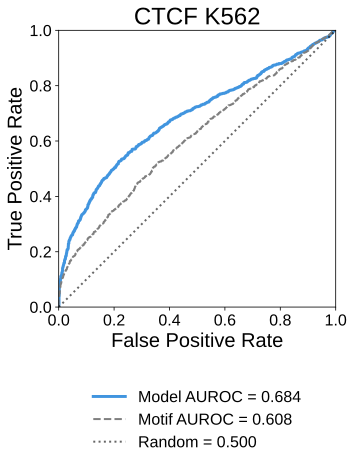

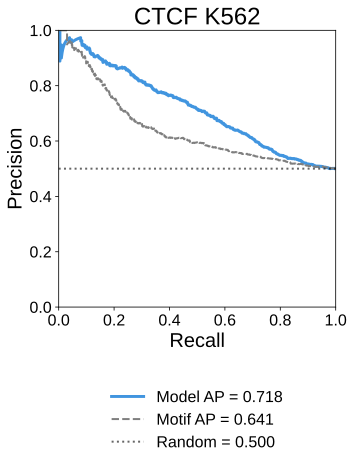

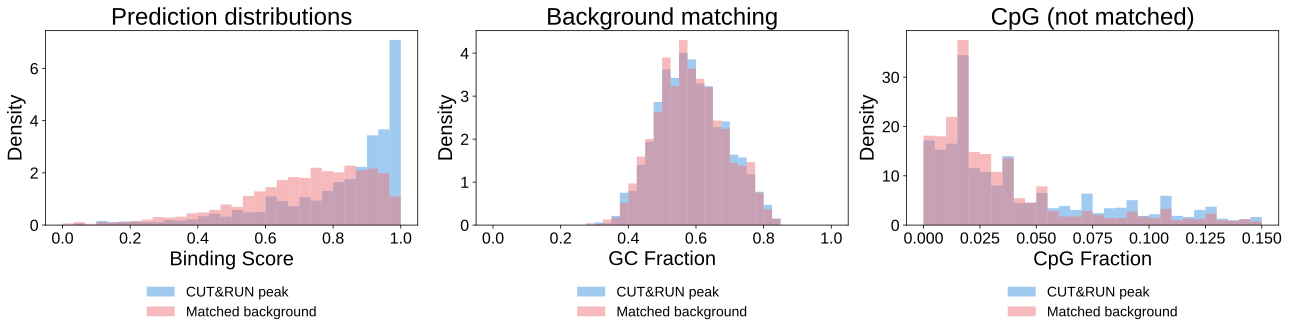

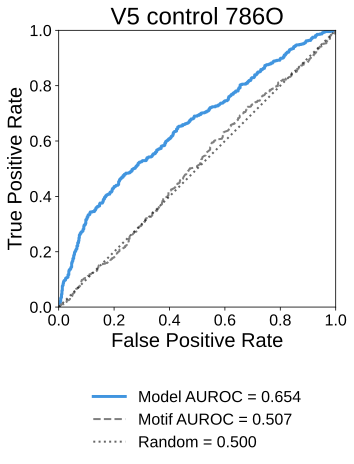

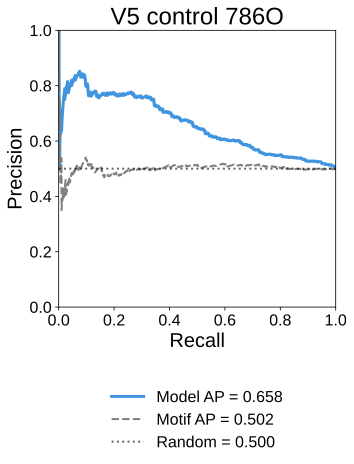

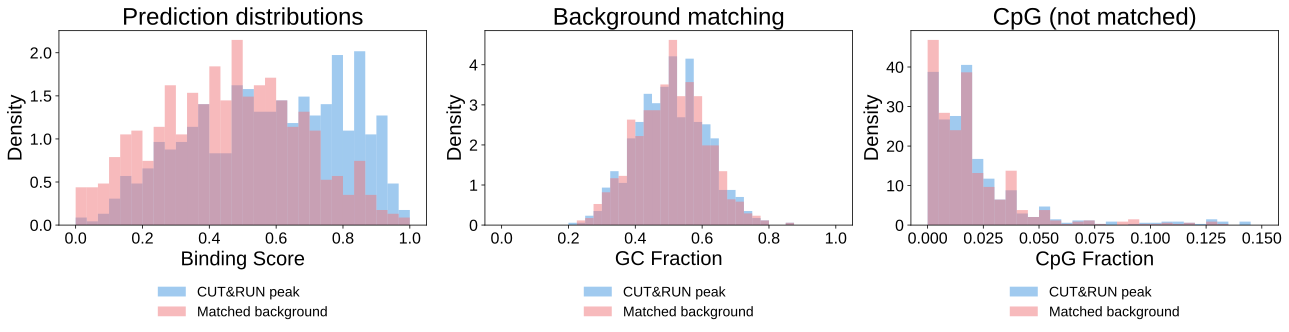

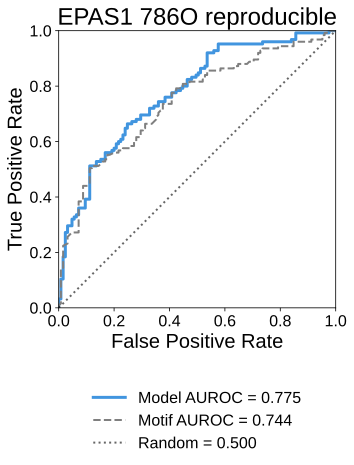

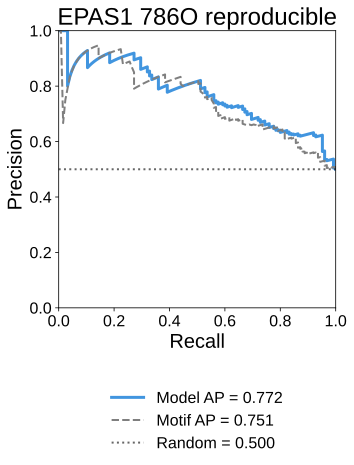

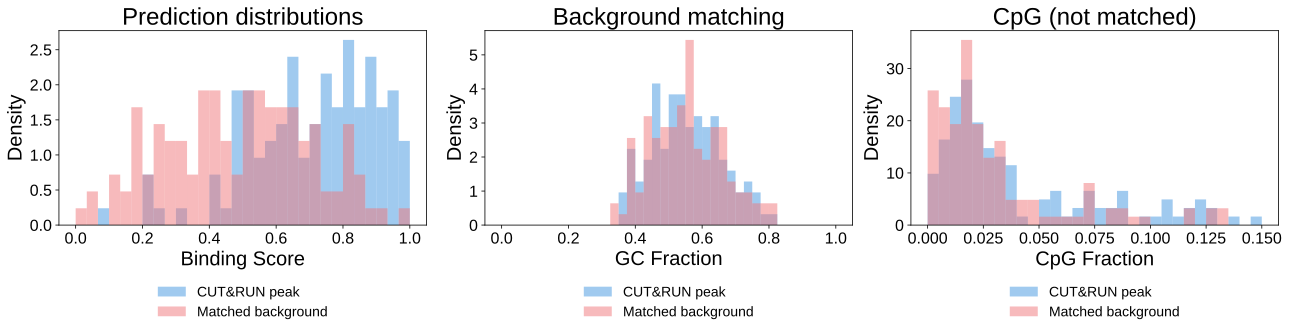

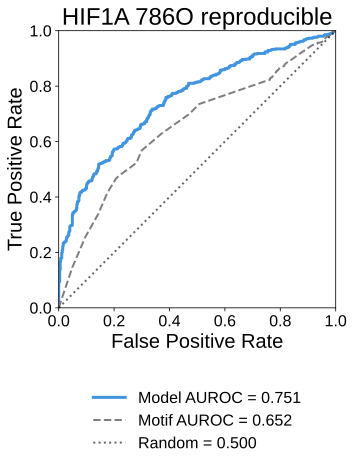

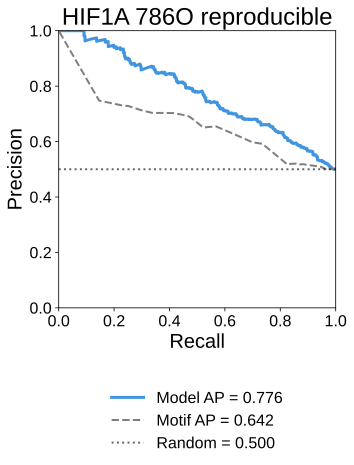

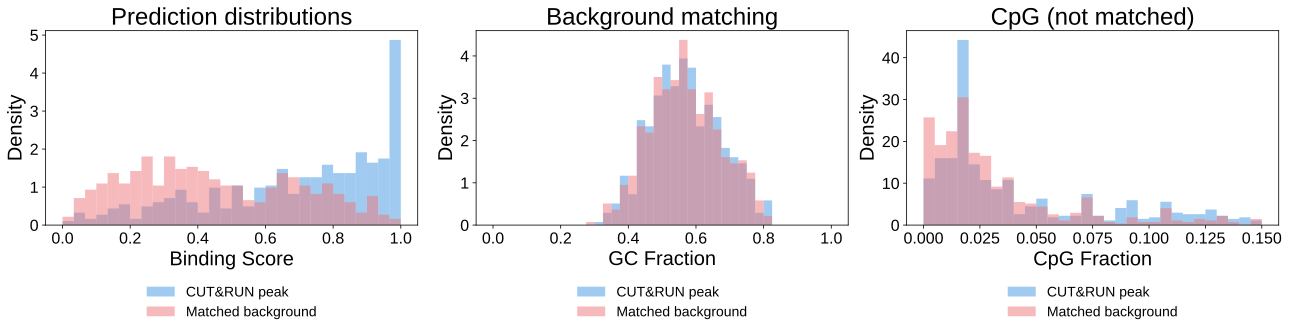

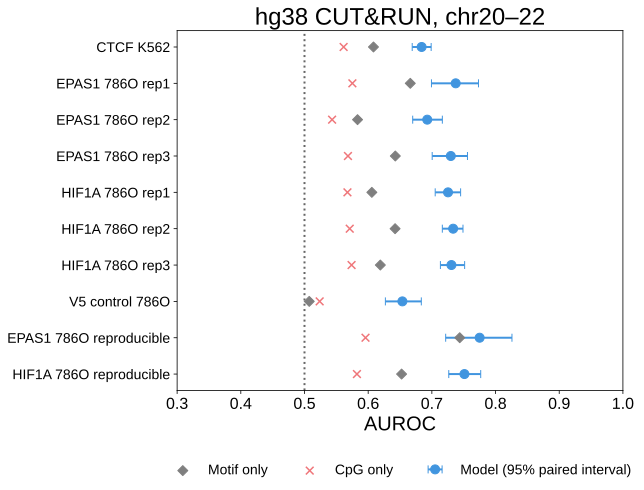

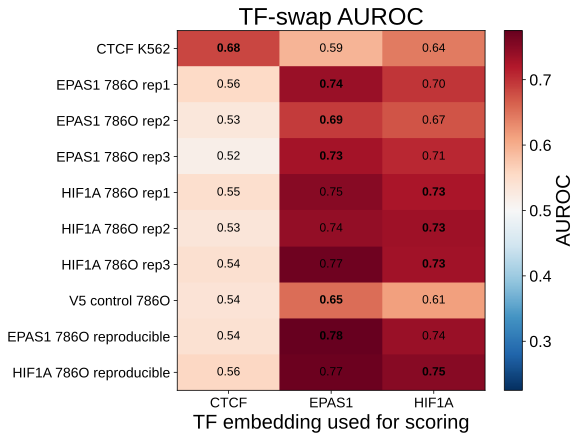

In [11]:
arial_font_path = TETHER_DIR / "fonts" / "Arial.ttf"
if arial_font_path.exists():
    font_manager.fontManager.addfont(str(arial_font_path))
    preferred_font = font_manager.FontProperties(fname=str(arial_font_path)).get_name()
else:
    preferred_font = "DejaVu Sans"
mpl.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": [preferred_font, "DejaVu Sans"],
    "pdf.fonttype": 42, "svg.fonttype": "none",
    "axes.titlesize": 24, "axes.labelsize": 20, "xtick.labelsize": 16, "ytick.labelsize": 16,
})
model_color = "#4195df"
motif_color = "#7f7f7f"
background_color = "#EF767A"

def save_evaluation_figure(figure, figure_stem):
    for extension in ("png", "pdf", "svg"):
        figure.savefig(evaluation_figure_dir / f"{figure_stem}.{extension}", dpi=300, bbox_inches="tight")

metrics_by_dataset = metric_summary_df.set_index("dataset")
for dataset_name, dataset_prediction_df in prediction_df.groupby("dataset", sort=False):
    dataset_metrics = metrics_by_dataset.loc[dataset_name]
    if dataset_metrics["role"] == "replicate":
        continue
    labels = dataset_prediction_df["label"].to_numpy()
    scores = dataset_prediction_df["binding_logit"].to_numpy()
    motif_scores = dataset_prediction_df["motif_score"].to_numpy()

    roc_figure, roc_axis = plt.subplots(figsize=(6, 5))
    false_positive_rate, true_positive_rate, _ = roc_curve(labels, scores)
    roc_axis.plot(false_positive_rate, true_positive_rate, color=model_color, lw=3,
                  label=f"Model AUROC = {dataset_metrics['auroc']:.3f}")
    false_positive_rate, true_positive_rate, _ = roc_curve(labels, motif_scores)
    roc_axis.plot(false_positive_rate, true_positive_rate, color=motif_color, lw=2, linestyle="--",
                  label=f"Motif AUROC = {dataset_metrics['motif_only_auroc']:.3f}")
    roc_axis.plot([0, 1], [0, 1], color="black", linestyle=":", lw=2, alpha=0.6, label="Random = 0.500")
    roc_axis.set(xlim=(0, 1), ylim=(0, 1), xlabel="False Positive Rate",
                 ylabel="True Positive Rate", title=dataset_name.replace("_", " "))
    roc_axis.set_aspect("equal")
    roc_axis.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), frameon=False, fontsize=16)
    save_evaluation_figure(roc_figure, f"{dataset_name}_roc")
    plt.show()
    plt.close(roc_figure)

    pr_figure, pr_axis = plt.subplots(figsize=(6, 5))
    precision, recall, _ = precision_recall_curve(labels, scores)
    pr_axis.plot(recall, precision, color=model_color, lw=3,
                 label=f"Model AP = {dataset_metrics['average_precision']:.3f}")
    precision, recall, _ = precision_recall_curve(labels, motif_scores)
    pr_axis.plot(recall, precision, color=motif_color, lw=2, linestyle="--",
                 label=f"Motif AP = {dataset_metrics['motif_only_average_precision']:.3f}")
    pr_axis.axhline(labels.mean(), color="black", linestyle=":", lw=2, alpha=0.6,
                    label=f"Random = {labels.mean():.3f}")
    pr_axis.set(xlim=(0, 1), ylim=(0, 1), xlabel="Recall", ylabel="Precision",
                title=dataset_name.replace("_", " "))
    pr_axis.set_aspect("equal")
    pr_axis.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), frameon=False, fontsize=16)
    save_evaluation_figure(pr_figure, f"{dataset_name}_precision_recall")
    plt.show()
    plt.close(pr_figure)

    diagnostic_figure, diagnostic_axes = plt.subplots(1, 3, figsize=(18, 5))
    for label, class_name, class_color in (
        (1, "CUT&RUN peak", model_color), (0, "Matched background", background_color),
    ):
        class_rows = dataset_prediction_df.loc[dataset_prediction_df["label"] == label]
        diagnostic_axes[0].hist(class_rows["binding_score"], bins=np.linspace(0, 1, 31),
                                density=True, alpha=0.5, color=class_color, label=class_name)
        diagnostic_axes[1].hist(class_rows["gc_fraction"], bins=np.linspace(0, 1, 41),
                                density=True, alpha=0.5, color=class_color, label=class_name)
        diagnostic_axes[2].hist(class_rows["cpg_fraction"], bins=np.linspace(0, 0.15, 31),
                                density=True, alpha=0.5, color=class_color, label=class_name)
    diagnostic_axes[0].set(xlabel="Binding Score", ylabel="Density", title="Prediction distributions")
    diagnostic_axes[1].set(xlabel="GC Fraction", ylabel="Density", title="Background matching")
    diagnostic_axes[2].set(xlabel="CpG Fraction", ylabel="Density", title="CpG (not matched)")
    for axis in diagnostic_axes:
        axis.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), frameon=False, fontsize=14)
    diagnostic_figure.tight_layout()
    save_evaluation_figure(diagnostic_figure, f"{dataset_name}_diagnostics")
    plt.show()
    plt.close(diagnostic_figure)

# Summary: model AUROC with paired interval, and the single-feature baselines, for every dataset.
summary_order = metric_summary_df.iloc[::-1].reset_index(drop=True)
summary_figure, summary_axis = plt.subplots(figsize=(8, 0.5 * len(summary_order) + 1.5))
y_positions = np.arange(len(summary_order))
summary_axis.errorbar(
    summary_order["auroc"], y_positions,
    xerr=[summary_order["auroc"] - summary_order["auroc_ci_low"],
          summary_order["auroc_ci_high"] - summary_order["auroc"]],
    fmt="o", color=model_color, ms=9, lw=2, capsize=4, label="Model (95% paired interval)",
)
summary_axis.scatter(summary_order["motif_only_auroc"], y_positions, marker="D", s=50,
                     color=motif_color, label="Motif only", zorder=3)
summary_axis.scatter(summary_order["cpg_only_auroc"], y_positions, marker="x", s=60,
                     color=background_color, label="CpG only", zorder=3)
summary_axis.axvline(0.5, color="black", linestyle=":", lw=2, alpha=0.6)
summary_axis.set_yticks(y_positions, summary_order["dataset"].str.replace("_", " "), fontsize=14)
chromosome_label = f"{EVALUATION_CHROMOSOMES[0]}–{EVALUATION_CHROMOSOMES[-1].removeprefix('chr')}"
summary_axis.set(xlim=(0.3, 1.0), xlabel="AUROC", title=f"{GENOME} CUT&RUN, {chromosome_label}")
# Place the legend a fixed 0.85 inch below the axis so it clears the x label at any figure height.
axis_height_inches = summary_axis.get_position().height * summary_figure.get_figheight()
summary_axis.legend(loc="upper center", bbox_to_anchor=(0.5, -0.85 / axis_height_inches),
                    frameon=False, fontsize=14, ncol=3)
save_evaluation_figure(summary_figure, "auroc_summary")
plt.show()
plt.close(summary_figure)

swap_values = tf_swap_matrix[EVALUATED_TFS]
swap_figure, swap_axis = plt.subplots(figsize=(1.3 * len(EVALUATED_TFS) + 3, 0.5 * len(swap_values) + 1.5))
# Diverging scale centered on random (0.5): values below 0.5 mean the embedding ranks peaks below background.
color_half_range = max(0.25, float((swap_values - 0.5).abs().max().max()))
image = swap_axis.imshow(swap_values.to_numpy(), cmap="RdBu_r", vmin=0.5 - color_half_range,
                         vmax=0.5 + color_half_range, aspect="auto")
for (row_index, column_index), value in np.ndenumerate(swap_values.to_numpy()):
    own_tf = metrics_by_dataset.loc[swap_values.index[row_index], "tf_name"]
    weight = "bold" if EVALUATED_TFS[column_index] == own_tf else "normal"
    swap_axis.text(column_index, row_index, f"{value:.2f}", ha="center", va="center", fontsize=12, fontweight=weight)
swap_axis.set_xticks(range(len(EVALUATED_TFS)), EVALUATED_TFS, fontsize=14)
swap_axis.set_yticks(range(len(swap_values)), swap_values.index.str.replace("_", " "), fontsize=14)
swap_axis.set(xlabel="TF embedding used for scoring", title="TF-swap AUROC")
swap_figure.colorbar(image, ax=swap_axis, label="AUROC")
save_evaluation_figure(swap_figure, "tf_swap_auroc")
plt.show()
plt.close(swap_figure)

## Reproducibility record and interpretation

The run records the checkpoint, input checksums, saved split audit, embedding check, motif choice, matching rules, package versions, compute host, and Slurm job. Prediction tables keep the exact evaluation row order and DNA sequences. Download commands are in `TETHER/bash_scripts/download_hg38_cutrun_peaks.sh`.

Interpretation is limited to sequence discrimination for these TFs, assays, chromosomes, and backgrounds. The model receives no cell-state, accessibility, TF-expression, or cofactor measurements. A good result supports sequence-based enrichment at CUT&RUN peaks; it cannot establish cell-type-specific occupancy. The CTCF peaks were lifted from hg19 and come from merged replicates, so their replicate structure differs from the HIF sets.

In [12]:
def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(8 * 1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

provenance_input_paths = [
    tf_dna_model_path, evaluation_windows_path,
    *sorted({cutrun_data_dir / filename for item in cutrun_dataset_definitions
             for filename in item["files"] if (cutrun_data_dir / filename).is_file()}),
    *[tf_dna_input_cache_dir / filename for filename in (
        "train_idx.pt", "val_idx.pt", "test_idx.pt", "edge_peak_idx.pt",
        "peak_id_to_idx.csv", "tf_name_to_idx.csv", "tf_masks.pt",
    )],
    cutrun_data_dir / f"{GENOME}-blacklist.v2.bed.gz",
    cutrun_data_dir / f"{GENOME}.chrom.sizes",
    *[cutrun_data_dir / filename for filename in EXTRA_PROVENANCE_FILES],
    *[cutrun_data_dir / f"{series}_family.soft.gz" for series in geo_metadata_by_series],
    Path(str(genome_fasta_path) + ".fai"),
]
run_provenance = dict(
    completed_utc=datetime.now(timezone.utc).isoformat(),
    host=socket.gethostname(),
    slurm_job_id=os.environ.get("TF_DNA_CUTRUN_BATCH_JOB_ID", os.environ.get("SLURM_JOB_ID")),
    kernel_environment_slurm_job_id=os.environ.get("SLURM_JOB_ID"),
    genome=GENOME, checkpoint=str(tf_dna_model_path), tf_dna_cache=str(tf_dna_input_cache_dir), device=str(device),
    gpu=torch.cuda.get_device_name() if device.type == "cuda" else None,
    python=platform.python_version(), torch=torch.__version__,
    numpy=np.__version__, pandas=pd.__version__, sklearn=sklearn.__version__,
    matplotlib=mpl.__version__, pysam=pysam.__version__,
    chromosomes=EVALUATION_CHROMOSOMES, random_seed=RANDOM_SEED,
    window_length=DNA_WINDOW_LENGTH, gc_tolerance=GC_MATCH_TOLERANCE,
    maximum_matching_attempts=MAXIMUM_MATCH_ATTEMPTS,
    inference_batch_size=INFERENCE_BATCH_SIZE, bootstrap_replicates=BOOTSTRAP_REPLICATES,
    score_orientation="forward genomic (primary); reverse complement reported",
    center="valid narrowPeak summit; midpoint for BED or invalid summit",
    tf_embedding_source="training cache tf_embeddings.pt with tf_masks.pt",
    embedding_check=embedding_check_df.to_dict(orient="records"),
    motifs=motif_records,
    datasets=[{key: value for key, value in item.items()} for item in cutrun_dataset_definitions],
    reference=dict(path=str(genome_fasta_path), size_bytes=genome_fasta_path.stat().st_size,
                   mtime_ns=genome_fasta_path.stat().st_mtime_ns,
                   validation=f"chromosome lengths match downloaded UCSC {GENOME} chromosome sizes"),
    file_sha256={str(path): sha256_file(path) for path in provenance_input_paths},
)
(evaluation_result_dir / "run_provenance.json").write_text(json.dumps(run_provenance, indent=2, default=str) + "\n")

chromosome_label = f"{EVALUATION_CHROMOSOMES[0]}–{EVALUATION_CHROMOSOMES[-1].removeprefix('chr')}"
interpretation_lines = [
    "### Observed results",
    "",
    f"All results compare {chromosome_label} CUT&RUN peaks with 1:1 chromosome- and GC-matched genomic background.",
    "",
    "| Dataset | Role | Positive windows | Model AUROC (95% paired interval) | Model AP | Motif-only AUROC | Model − motif (95% interval) | CpG-only AUROC |",
    "|---|---|---:|---:|---:|---:|---:|---:|",
]
for row in metric_summary_df.itertuples(index=False):
    interpretation_lines.append(
        f"| {row.dataset} | {row.role} | {row.positive_windows:,} | "
        f"{row.auroc:.3f} ({row.auroc_ci_low:.3f}–{row.auroc_ci_high:.3f}) | {row.average_precision:.3f} | "
        f"{row.motif_only_auroc:.3f} | {row.model_minus_motif_auroc:+.3f} "
        f"({row.model_minus_motif_auroc_ci_low:+.3f} to {row.model_minus_motif_auroc_ci_high:+.3f}) | "
        f"{row.cpg_only_auroc:.3f} |"
    )
interpretation_lines += [
    "",
    "Random ranking gives AUROC 0.5 and expected AP 0.5 in this balanced sample. "
    "The intervals describe sampled loci and do not establish biological replicate uncertainty.",
    "",
    f"Predictions and methods records: {evaluation_result_dir}",
    f"Figures: {evaluation_figure_dir}",
]
interpretation_markdown = "\n".join(interpretation_lines)
(evaluation_result_dir / "results_summary.md").write_text(interpretation_markdown + "\n")
display(Markdown(interpretation_markdown))
genome_fasta.close()

### Observed results

All results compare chr20–22 CUT&RUN peaks with 1:1 chromosome- and GC-matched genomic background.

| Dataset | Role | Positive windows | Model AUROC (95% paired interval) | Model AP | Motif-only AUROC | Model − motif (95% interval) | CpG-only AUROC |
|---|---|---:|---:|---:|---:|---:|---:|
| CTCF_K562 | primary | 1,857 | 0.684 (0.669–0.699) | 0.718 | 0.608 | +0.076 (+0.059 to +0.093) | 0.561 |
| EPAS1_786O_rep1 | replicate | 281 | 0.737 (0.699–0.773) | 0.715 | 0.666 | +0.071 (+0.020 to +0.128) | 0.575 |
| EPAS1_786O_rep2 | replicate | 857 | 0.693 (0.670–0.716) | 0.704 | 0.583 | +0.109 (+0.078 to +0.139) | 0.543 |
| EPAS1_786O_rep3 | replicate | 531 | 0.730 (0.701–0.756) | 0.726 | 0.643 | +0.087 (+0.050 to +0.126) | 0.568 |
| HIF1A_786O_rep1 | replicate | 1,146 | 0.725 (0.705–0.745) | 0.744 | 0.606 | +0.120 (+0.091 to +0.144) | 0.567 |
| HIF1A_786O_rep2 | replicate | 1,505 | 0.733 (0.716–0.749) | 0.753 | 0.642 | +0.091 (+0.065 to +0.113) | 0.571 |
| HIF1A_786O_rep3 | replicate | 1,153 | 0.731 (0.713–0.751) | 0.749 | 0.619 | +0.112 (+0.086 to +0.138) | 0.574 |
| V5_control_786O | control | 684 | 0.654 (0.627–0.683) | 0.658 | 0.507 | +0.146 (+0.108 to +0.186) | 0.524 |
| EPAS1_786O_reproducible | primary | 125 | 0.775 (0.722–0.826) | 0.772 | 0.744 | +0.031 (-0.050 to +0.110) | 0.596 |
| HIF1A_786O_reproducible | primary | 548 | 0.751 (0.727–0.777) | 0.776 | 0.652 | +0.099 (+0.059 to +0.137) | 0.582 |

Random ranking gives AUROC 0.5 and expected AP 0.5 in this balanced sample. The intervals describe sampled loci and do not establish biological replicate uncertainty.

Predictions and methods records: /gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER/TETHER/new_testing_results/tf_dna_cutrun_hg38_hg38_3930720_epoch_18
Figures: /gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER/TETHER/new_plots/tf_dna_cutrun_hg38_hg38_3930720_epoch_18

## Findings from the completed evaluation

All numbers are for chr20–22, which the saved-cache audit shows are absent from the training split (chr1–17) and the validation split (chr18–19). Each dataset is 1:1 positive/GC-matched background, so random AUROC and AP are 0.5. GC-only AUROC is 0.50–0.51 for every dataset, so the background matching worked. All peak sets except the V5 control pass motif QC.

**HIF factors (786-O): the model ranks HIF peaks above background.** For the reproducible, control-free sets, AUROC is **0.775** for endogenous EPAS1 (125 pairs, 95% paired interval 0.722–0.826) and **0.751** for exogenous HIF1A (548 pairs, 0.727–0.777). Single replicates give 0.693–0.737 (EPAS1) and 0.725–0.733 (HIF1A). Per-chromosome AUROCs of the reproducible sets agree (0.72–0.82). Compared with one CIS-BP PWM scan, the model is better for HIF1A (+0.099, interval +0.059 to +0.137); for EPAS1 the difference is not resolved (+0.031, −0.050 to +0.110).

**A large part of the HIF signal does not depend on the TF.** The wild-type anti-V5 peaks have no tagged protein and no RCGTG enrichment (PWM AUROC 0.507), but the model with the EPAS1 embedding ranks them at AUROC **0.654** (0.627–0.683). CpG does not explain this (CpG-only AUROC 0.524). Thus only about 0.10–0.12 of the reproducible-set HIF AUROC is above what the model gives to non-specific CUT&RUN peaks from the same cells.

**TF identity matters, at the level of the motif family.** On every HIF peak set, the EPAS1 and HIF1A embeddings give AUROC 0.67–0.77 and the CTCF embedding gives 0.52–0.56. The two HIF-α embeddings are close to interchangeable, as expected from their shared motif; the EPAS1 embedding scores slightly higher on both HIF factors' peaks.

**CTCF (K562, lifted from hg19): moderate.** AUROC is **0.684** (1,857 pairs, 0.669–0.699), AP 0.718, and 0.076 above the PWM scan (+0.059 to +0.093). The CTCF embedding ranks these peaks best (next best HIF1A, 0.643). At threshold 0.5, sensitivity is 0.915 and specificity 0.138: the CTCF embedding scores most windows as bound, so only the ranking is useful. This is in the range of the mm10 CTCF result (0.59–0.64).

**Caveats.** Forward-strand and strand-averaged AUROCs differ by 0.01 or less. A previous run of this notebook with two more datasets drew different backgrounds (the seed depends on dataset order) and moved single-dataset AUROCs by up to 0.03; differences smaller than this are not meaningful. No lineage-restricted human TF is included: the GATA2/GATA3 trophoblast peaks (GSE214486) had no GATA motif enrichment, and wild-type TAL1 CUT&RUN in K562 (Matur et al. 2025, GSE272339 and the lab's own MACS2 calls) has 41 peaks genome-wide, none on chr20–22.

**Comparison with mm10 (same analysis cells, `mm10_tf_dna_vs_cut&run.ipynb`).** The lineage-restricted TFs score similarly (mm10 NANOG 0.759; hg38 EPAS1 0.775, HIF1A 0.751). CTCF differs: hg38 3930720 is above the CTCF PWM (+0.076), and mm10 3925194 is below it (−0.022 and −0.054). TF specificity is weaker in hg38: out-of-family embeddings score 0.52–0.56 on HIF peaks here, but 0.29–0.46 in mm10. mm10 has no no-TF control, so the 0.65 control result cannot be compared.